# 01 · Análisis exploratorio de PM2.5 en el Valle de Aburrá

**Fuente de los datos.** Conjunto [Calidad del Aire en Colombia](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Calidad-del-Aire-en-Colombia/g4t8-zkc3) (SISAIRE, IDEAM) de datos.gov.co, filtrado por la autoridad ambiental AMVA y la variable PM2.5. Son mediciones horarias en µg/m³ de 2022 a 2025.

**Antes de ejecutar:** `python -m src.download_data` y `python -m src.preprocess` (el repositorio ya incluye la tabla diaria procesada).

El preprocesamiento (`src/preprocess.py`) descarta valores imposibles, elimina duplicados, calcula el promedio diario solo para los días con al menos 18 de 24 horas medidas y descarta los meses con la escala corrupta (sección 1). Este notebook parte de esa tabla diaria.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, features, ica, preprocess

plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

diario = preprocess.cargar_diario()
estaciones = preprocess.cargar_estaciones()
print(f"{len(diario):,} días-estación · {diario['estacion'].nunique()} estaciones · {diario['fecha'].min():%Y-%m-%d} a {diario['fecha'].max():%Y-%m-%d}")
diario.head()

21,245 días-estación · 25 estaciones · 2022-01-01 a 2025-12-31


,fecha,estacion,municipio,pm25,horas_validas,categoria
0,2023-12-01,ALMACÉN GENERAL DE EPM,Medellín,19.0,23,Aceptable
1,2023-12-02,ALMACÉN GENERAL DE EPM,Medellín,16.9,24,Aceptable
2,2023-12-03,ALMACÉN GENERAL DE EPM,Medellín,16.0,24,Aceptable
3,2023-12-04,ALMACÉN GENERAL DE EPM,Medellín,18.7,24,Aceptable
4,2023-12-07,ALMACÉN GENERAL DE EPM,Medellín,24.9,19,Aceptable


## 1. Calidad de los datos: el punto decimal perdido

Al revisar la primera versión de la tabla diaria aparecieron promedios de 100 a 300 µg/m³, imposibles para esta red. La causa está en la fuente: en 2022 y 2023, 14 estaciones tienen los valores **sin punto decimal**. Por ejemplo, la estación Altavista reporta el 1 de febrero de 2023 valores horarios de 399, 387 y 304, y el 3 de febrero de 2949 y 3061; un año después, en las mismas fechas, reporta 26.0, 24.8 y 22.4.

- Los valores con dos decimales (29.49 → 2949) superan 500 µg/m³ y ya los eliminaba el filtro de valores imposibles.
- Los valores con un decimal (39.9 → 399) sobrevivían multiplicados por 10. En la fuente solo los dos primeros días de cada mes vienen con un decimal, y por eso el defecto se veía como «uno o dos días por mes con valores enormes».

No se puede saber con certeza qué factor aplicar a cada valor, así que **no se corrigen: se descartan**. La regla compara cada estación con la red de referencia del mismo día (la mediana de las estaciones con al menos 300 días válidos ese año, que no pueden estar afectadas porque el defecto destruye la cobertura). Un mes-estación se descarta si su nivel relativo a la red supera 2.5 veces el nivel relativo habitual de esa estación. Comparar contra la red del mismo día cancela la estacionalidad.

La tabla siguiente es el registro de lo descartado (`data/processed/descartes_escala.csv`).

In [2]:
descartes = pd.read_csv(config.DISCARDS_CSV)
print(f"Descartados: {descartes['dias_descartados'].sum():,} días-estación en {len(descartes)} meses de {descartes['estacion'].nunique()} estaciones")
print(f"Razón frente al nivel habitual de la estación: mínima {descartes['razon'].min()}, mediana {descartes['razon'].median()}")
resumen = descartes.assign(anio=descartes["mes"].str[:4]).pivot_table(index="estacion", columns="anio", values="dias_descartados", aggfunc="sum", fill_value=0)
resumen["mediana_pm25_descartada"] = descartes.groupby("estacion")["mediana_pm25"].median().round(0)
resumen

Descartados: 927 días-estación en 275 meses de 14 estaciones
Razón frente al nivel habitual de la estación: mínima 3.4, mediana 7.8


anio,2022,2023,mediana_pm25_descartada
estacion,,,
ALTAVISTA,20,51,149.0
BIBLIOTECA FERNANDO B.,20,43,149.0
CIUDADELA EDUCATIVA,19,49,116.0
ESCUELA JOAQUÍN A.,21,52,132.0
HOSPITAL MANUEL URIBE,23,50,137.0
I.E. CIRO MENDIA,21,48,162.0
I.E. JOSÉ FÉLIX,43,2,150.0
I.E. PEDRO JUSTO B.,22,52,167.0
I.E. RAFAEL J. MEJÍA,22,51,143.0


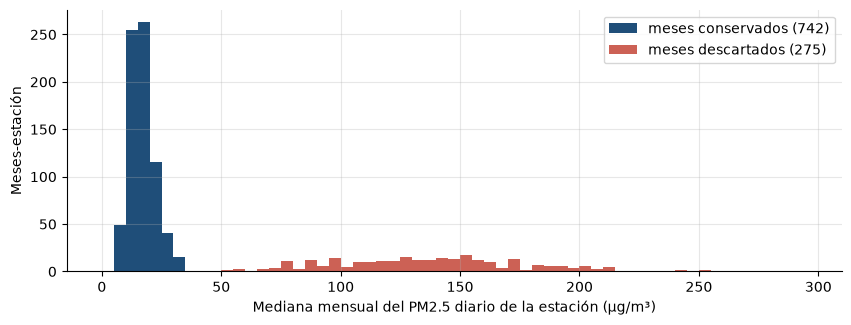

Mayor mediana mensual conservada: 42.8 µg/m³ · menor mediana mensual descartada: 46.8 µg/m³


In [3]:
# Los meses descartados frente a los conservados: no hay solapamiento entre los dos grupos.
medianas_ok = diario.groupby(["estacion", diario["fecha"].dt.to_period("M")])["pm25"].median()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(medianas_ok, bins=np.arange(0, 300, 5), color="#1F4E79", label=f"meses conservados ({len(medianas_ok)})")
ax.hist(descartes["mediana_pm25"], bins=np.arange(0, 300, 5), color="#C0392B", alpha=0.8, label=f"meses descartados ({len(descartes)})")
ax.set_xlabel("Mediana mensual del PM2.5 diario de la estación (µg/m³)"); ax.set_ylabel("Meses-estación"); ax.legend()
plt.show()
print(f"Mayor mediana mensual conservada: {medianas_ok.max():.1f} µg/m³ · menor mediana mensual descartada: {descartes['mediana_pm25'].min():.1f} µg/m³")

Las medianas mensuales se solapan un poco en valor absoluto (una estación limpia como Santa Elena, multiplicada por 10, queda cerca de un mes real de episodio en una estación de tráfico), y por eso la regla no usa un umbral absoluto sino el nivel relativo a la red: con ese criterio la mayor razón entre los meses sanos es 1.5 y la menor entre los corruptos es 3.4.

**Consecuencia para el resto del proyecto:** las 14 estaciones afectadas solo aportan datos desde 2024. En 2022 y 2023 quedan 9 estaciones.

## 2. Cobertura: días válidos por estación y año

Una estación con muchos vacíos aporta menos ejemplos al modelo y más días sin predicción en el dashboard.

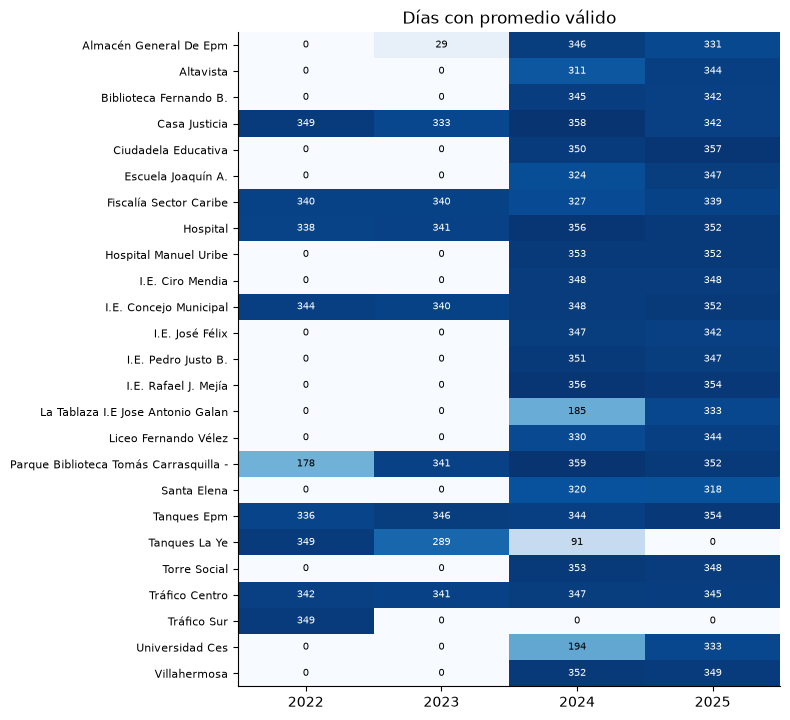

Estaciones con dato por año: {2022: 9, 2023: 9, 2024: 24, 2025: 23}


In [4]:
cobertura = diario.pivot_table(index="estacion", columns=diario["fecha"].dt.year, values="pm25", aggfunc="size", fill_value=0)
fig, ax = plt.subplots(figsize=(7, 0.3 * len(cobertura) + 1))
im = ax.imshow(cobertura.to_numpy(), cmap="Blues", aspect="auto", vmin=0, vmax=366)
ax.set_xticks(range(cobertura.shape[1])); ax.set_xticklabels(cobertura.columns)
ax.set_yticks(range(len(cobertura))); ax.set_yticklabels([e.title()[:38] for e in cobertura.index], fontsize=8)
for i in range(cobertura.shape[0]):
    for j in range(cobertura.shape[1]):
        v = cobertura.iat[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=7, color="white" if v > 200 else "black")
ax.grid(False); ax.set_title("Días con promedio válido")
plt.show()
print("Estaciones con dato por año:", (cobertura > 0).sum().to_dict())

## 3. Distribución del PM2.5 diario y de las categorías ICA

Las líneas verticales son los puntos de corte del ICA para PM2.5 de 24 horas (Resolución 2254 de 2017): 12, 37 y 55 µg/m³.

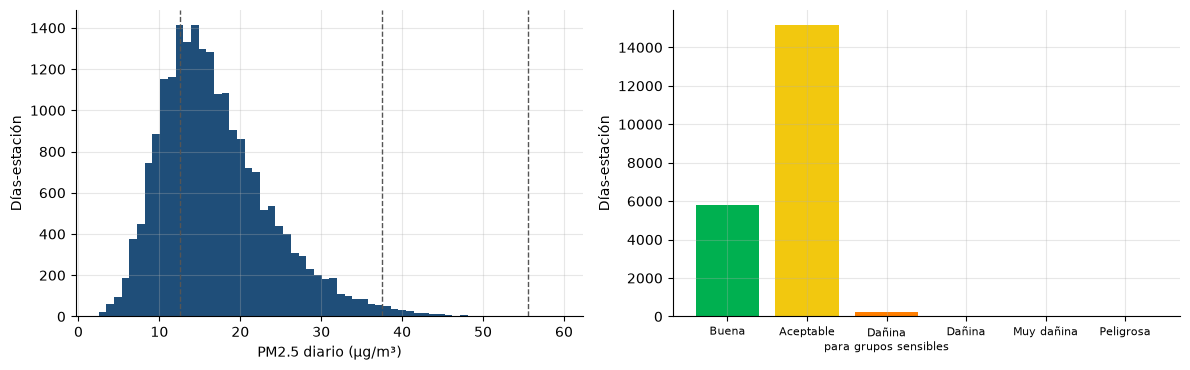

,dias,fraccion
categoria,,
Buena,5816,0.2738
Aceptable,15186,0.7148
Dañina para grupos sensibles,242,0.0114
Dañina,1,0.0000
Muy dañina,0,0.0000
Peligrosa,0,0.0000


In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8))
a.hist(diario["pm25"], bins=60, color="#1F4E79")
for corte in features.BORDES_CLASE:
    a.axvline(corte, color="#555", ls="--", lw=1)
a.set_xlabel("PM2.5 diario (µg/m³)"); a.set_ylabel("Días-estación")

conteo = diario["categoria"].value_counts().reindex(ica.NOMBRES, fill_value=0)
b.bar(range(len(conteo)), conteo.values, color=[ica.COLORES[c] for c in conteo.index])
b.set_xticks(range(len(conteo))); b.set_xticklabels([c.replace(" para ", "\npara ") for c in conteo.index], fontsize=8)
b.set_ylabel("Días-estación")
plt.tight_layout(); plt.show()
pd.DataFrame({"dias": conteo, "fraccion": (conteo / conteo.sum()).round(4)})

## 4. Estacionalidad y diferencias entre años

En el valle se habla de dos temporadas de episodios (febrero-abril y octubre-noviembre), asociadas a la transición entre la época seca y la de lluvias. Aquí se comprueba qué meses y qué años concentran los valores altos.

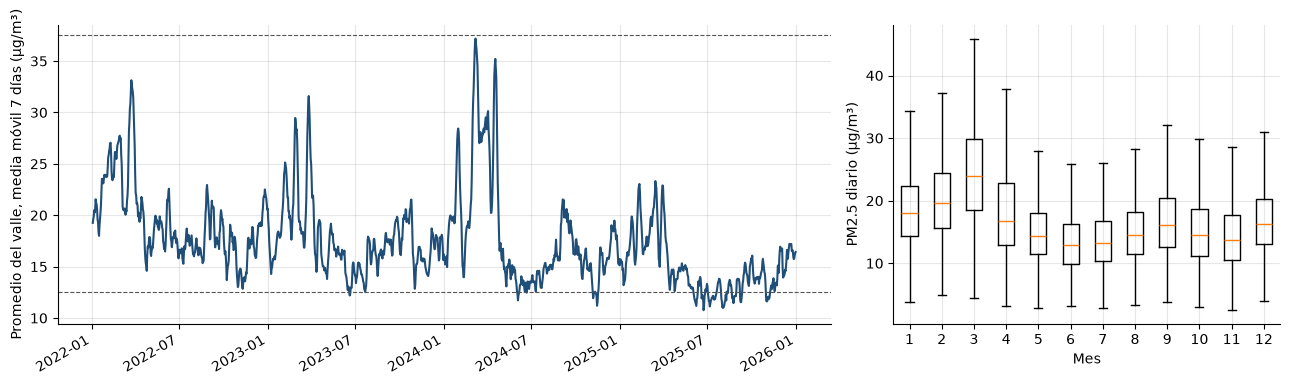

Fracción de días-estación en episodio (Dañina para grupos sensibles o peor) por mes:


fecha,1,2,3,4,5,6,7,8,9,10,11,12
fracción,0.007,0.023,0.071,0.033,0.0,0.0,0.0,0.001,0.001,0.001,0.001,0.002


Días-estación en episodio por año:


,dias_estacion,en_episodio,pm25_medio
fecha,,,
2022,2925,28,19.1
2023,2700,4,17.3
2024,7695,204,18.2
2025,7925,7,14.9


In [6]:
valle = diario.groupby("fecha")["pm25"].mean()
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
valle.rolling(7, min_periods=3).mean().plot(ax=a, color="#1F4E79")
for corte in features.BORDES_CLASE[:2]:
    a.axhline(corte, color="#555", ls="--", lw=0.8)
a.set_ylabel("Promedio del valle, media móvil 7 días (µg/m³)"); a.set_xlabel("")

por_mes = [diario.loc[diario["fecha"].dt.month == m, "pm25"].to_numpy() for m in range(1, 13)]
b.boxplot(por_mes, showfliers=False)
b.set_xlabel("Mes"); b.set_ylabel("PM2.5 diario (µg/m³)")
plt.tight_layout(); plt.show()

episodio = diario.assign(episodio=features.clase_de(diario["pm25"]) >= ica.CLASE_EPISODIO)
print("Fracción de días-estación en episodio (Dañina para grupos sensibles o peor) por mes:")
display(episodio.groupby(episodio["fecha"].dt.month)["episodio"].mean().round(3).to_frame("fracción").T)
print("Días-estación en episodio por año:")
episodio.groupby(episodio["fecha"].dt.year).agg(dias_estacion=("pm25", "size"), en_episodio=("episodio", "sum"), pm25_medio=("pm25", "mean")).round(1)

**Lectura.** Los episodios se concentran en febrero-abril, con el máximo en marzo. La segunda temporada (octubre-noviembre) prácticamente no aparece en estos cuatro años. Además, casi todos los días de episodio son de **2024**: 2025 fue un año muy limpio, con un puñado de días de episodio en todo el valle.

Esto condiciona la evaluación del modelo: con partición temporal, el año de prueba (2025) casi no tiene episodios, de modo que allí no se puede medir bien la capacidad de anticiparlos.

## 5. Día de la semana

Si el tráfico influye, los fines de semana deberían ser más limpios. De aquí sale la variable `dia_manana`.

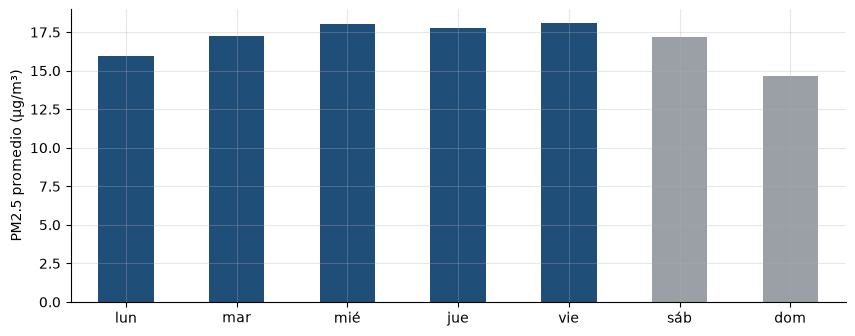

fecha,lun,mar,mié,jue,vie,sáb,dom
pm25_medio,16.0,17.3,18.0,17.8,18.1,17.2,14.6


In [7]:
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia = diario.groupby(diario["fecha"].dt.day_of_week)["pm25"].mean()
ax = por_dia.plot.bar(color=["#1F4E79"] * 5 + ["#9AA0A6"] * 2)
ax.set_xticklabels(dias, rotation=0); ax.set_xlabel(""); ax.set_ylabel("PM2.5 promedio (µg/m³)")
plt.show()
por_dia.round(1).rename(index=dict(enumerate(dias))).to_frame("pm25_medio").T

El domingo es el día más limpio y el lunes, que hereda el aire del domingo, el segundo. De martes a viernes el nivel es casi constante.

## 6. Persistencia: ¿cuánto se parece mañana a hoy?

Es la pregunta clave para el modelo. Si la clase de mañana casi siempre es la de hoy, la línea base de persistencia será difícil de superar y el valor del modelo estará en anticipar los cambios de categoría.

In [8]:
tabla = features.construir_tabla(diario).dropna(subset=["y"])
print(f"Correlación entre PM2.5 de hoy y de mañana: {tabla['pm25_hoy'].corr(tabla['pm25_manana']):.3f}")
print(f"Días en que mañana tiene la misma clase que hoy: {(tabla['clase_hoy'] == tabla['y']).mean():.1%}")

transicion = pd.crosstab(tabla["clase_hoy"], tabla["y"].astype(int), normalize="index")
transicion.index = [ica.CLASES[i] for i in transicion.index]
transicion.columns = [ica.CLASES[i] for i in transicion.columns]
print("\nP(clase de mañana | clase de hoy):")
transicion.round(3)

Correlación entre PM2.5 de hoy y de mañana: 0.802
Días en que mañana tiene la misma clase que hoy: 80.4%

P(clase de mañana | clase de hoy):


,Buena,Aceptable,Dañina para grupos sensibles,Dañina o peor
Buena,0.66,0.339,0.000,0.000
Aceptable,0.13,0.863,0.007,0.000
Dañina para grupos sensibles,0.00,0.472,0.524,0.004
Dañina o peor,0.00,0.000,1.000,0.000


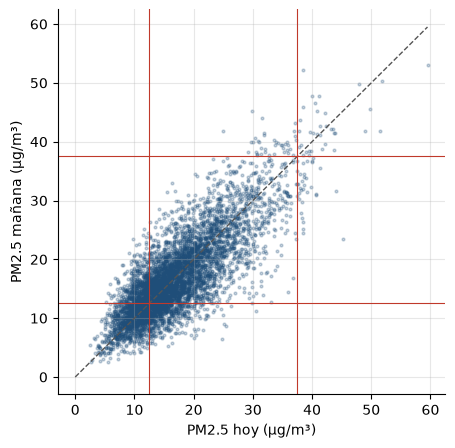

In [9]:
muestra = tabla.sample(min(len(tabla), 6000), random_state=0)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(muestra["pm25_hoy"], muestra["pm25_manana"], s=4, alpha=0.25, color="#1F4E79")
limite = float(max(muestra["pm25_hoy"].max(), muestra["pm25_manana"].max()))
ax.plot([0, limite], [0, limite], color="#555", lw=1, ls="--")
for corte in features.BORDES_CLASE[:2]:
    ax.axvline(corte, color="#C0392B", lw=0.8); ax.axhline(corte, color="#C0392B", lw=0.8)
ax.set_xlabel("PM2.5 hoy (µg/m³)"); ax.set_ylabel("PM2.5 mañana (µg/m³)")
plt.show()

**Lectura.** Cuatro de cada cinco días repiten la clase del día anterior, así que la persistencia es una línea base exigente. Los errores de la persistencia están donde la nube de puntos cruza las líneas rojas: días cercanos al corte de 12 µg/m³ (Buena / Aceptable), que es donde está la mayoría de los datos. Un día «Bueno» tiene una probabilidad de un tercio de pasar a «Aceptable» al día siguiente.

## 7. Qué se lleva el modelo de este análisis

- **Objetivo:** la clase ICA del día siguiente. Solo hay un día en «Dañina» y ninguno por encima, así que las categorías superiores se agrupan en «Dañina o peor».
- **Variables.** Como los errores se concentran cerca de los cortes, el nivel de hoy se discretiza en 14 niveles, más finos alrededor de 12 y 37 µg/m³. El promedio de los últimos 7 días aporta el nivel de fondo de la estación (hacia dónde tiende a volver). El tipo de día objetivo recoge el efecto del domingo (sección 5) y el cambio del promedio del valle indica si el aire de toda la región está mejorando o empeorando.
- **Lo que no entró.** Se probó una variable de temporada (sección 4) y no ayudó en validación: su información ya está en el nivel de la semana.
- **Línea base exigente:** la persistencia (sección 6).
- **Evaluación:** partición temporal, porque los días consecutivos están muy correlacionados y una partición aleatoria filtraría información. El año de prueba casi no tiene episodios (sección 4), y eso se declara como limitación.

El modelo, sus métricas y sus limitaciones están en `02_modelo.ipynb`.